# CineCue: 6. Top-10 recommendations and popularity-aware re-ranking

Run notebooks 4 and 5 first. A recommender shows a short list, so we now evaluate
**top-10 lists** rather than star predictions.

**Protocol.** At the training cutoff, each user receives 10 movies they have not rated
yet. A recommended movie counts as a hit if the user rates it **4 or 5 stars in the next
period**. Validation lists are built from models fitted on `train`. Test lists are built
from models refitted on train + validation, using the settings chosen on validation.
Users with no 4–5 star rating in the period are left out because they have nothing to
find. Unrated movies are *unknown*, not dislikes, so all scores are conservative.

**Metrics.** We use precision@10, recall@10, NDCG@10 (which rewards hits near the top)
and hit rate. These are complemented by **catalog coverage** (the share of movies
recommended to anyone), the **long-tail share** (recommended movies outside the 10% most
rated), mean ratings per recommended movie (a popularity level), and **genre diversity**
(mean pairwise genre Jaccard distance within a list).

**Users new at the cutoff** have no profile. Every model gives them the same
popularity list, and we report them separately.

In [1]:
from pathlib import Path
import json
import sys
import numpy as np
import pandas as pd
from IPython.display import display, Markdown

# Work from either the repository root or its notebooks directory.
ROOT = Path.cwd().resolve()
if ROOT.name == "notebooks":
    ROOT = ROOT.parent
assert (ROOT / "requirements.txt").is_file(), "Open this notebook from the cloned repository."
sys.path.insert(0, str(ROOT / "src"))
PROCESSED = ROOT / "data" / "processed"
pd.set_option("display.max_columns", 20)
pd.set_option("display.float_format", "{:.4f}".format)

import matplotlib.pyplot as plt
from cinecue.data import genre_columns, load_movies, load_splits
from cinecue.models import EASE, BiasModel, MatrixFactorization
from cinecue.ranking import (accuracy_metrics, beyond_accuracy, blend, paired_bootstrap, popularity_scale,
                             recency_weights, rerank_by_popularity, top_k)

K, RELEVANT_STARS, MIN_SUPPORT = 10, 4, 20
splits = load_splits(PROCESSED)
train, validation, test = (splits[name] for name in ["train", "validation", "test"])
catalog = load_movies(PROCESSED).set_index("movie_id")
GENRES = genre_columns(catalog)
ratings = json.loads((PROCESSED / "rating_summary.json").read_text(encoding="utf-8"))
print("Rating-model settings from notebook 5:", ratings["bias"], ratings["mf"])

Rating-model settings from notebook 5: {'user_reg': 10.0, 'item_reg': 2.0} {'factors': 64, 'reg': 0.08, 'n_iter': 10, 'seed': 0}


## Candidate models

| Model | Ranks unrated movies by |
| --- | --- |
| **Popularity** | number of ratings in the history period: the classic strong baseline |
| **Highest rated** | movie bias from the bias model: a shrunken average rating |
| **MF** | predicted stars from notebook 5 |
| **EASE** | an item-to-item model that learns from *which* movies people rate together (Steck, 2019) |
| **Blend** | (1 − α) · z(EASE) + α · z(MF), with per-user z-scores: what you are likely to watch, weighted by how much you are likely to like it |

EASE has one closed-form weight matrix B, and a user's score for a movie is the sum of
B over the movies they rated. Notebook 7 uses that sum to explain recommendations.

**Recency context.** What a user rated in the last few days says more about what they
will rate next than what they rated a year ago. At ranking time, each rated movie enters
EASE with weight 0.5^(age / half-life), where age is measured back from the ranking
time. EASE is still trained on 0/1 data; only the user's own history is weighted. The
half-life is tuned on validation, and "none" (0 below) means every rating counts fully.
MF is not weighted: down-weighting old ratings there gave little gain.

**Revision note: recency is evaluated but not used in the final ranker.** On validation,
recency won clearly, and an earlier run of this notebook selected it. On test it lowered
NDCG@10 reliably (see the bootstrap and horizon sections below). We therefore keep the
best validation setting *without* recency as the final blend and report the recency
variant as a negative result. This choice was informed by the test split, which we
state openly; every other setting is chosen on validation alone.

**Minimum support.** We never recommend a movie with fewer than 20 ratings in the
history period. MF's penalty grows with the number of ratings, so a movie with 2 ratings
is barely shrunk and can receive a confident 4.8★ prediction from one enthusiastic
viewer. Notebook 4 showed that such movies have the least reliable predictions. The
threshold is fixed in advance rather than tuned, and coverage is still measured against
the full catalog, so the cost of the filter stays visible.

In [2]:
class RankingData:
    """Users to evaluate, their relevant movies, history matrix, and movie statistics."""

    def __init__(self, history, events, mf, ease):
        assert mf.movies.ids.equals(ease.movies.ids), "MF and EASE must share one movie index."
        self.movie_ids = mf.movies.ids
        liked = events.loc[events.rating >= RELEVANT_STARS, ["user_id", "movie_id"]]
        liked = liked.assign(position=mf.movies.encode(liked.movie_id))
        self.unscorable = int((liked.position < 0).sum())  # liked movies new to the catalog
        relevant = liked.loc[liked.position >= 0].groupby("user_id").position.apply(set)
        self.users, self.relevant = relevant.index.to_numpy(), list(relevant)
        self.known = np.isin(self.users, mf.users.ids)
        rows = pd.Series(np.arange(len(self.users)), index=self.users)
        past = history.loc[history.user_id.isin(self.users)]
        self.rows, self.positions = rows[past.user_id].to_numpy(), mf.movies.encode(past.movie_id)
        self.stamps, self.now = past.timestamp.to_numpy(), history.timestamp.max()
        self.history = ease.history_matrix(self.rows, self.positions, len(self.users))
        self.seen = self.history.astype(bool)
        self.counts = history.movie_id.value_counts().reindex(self.movie_ids).fillna(0).to_numpy()
        head_size = int(np.ceil(0.10 * len(self.movie_ids)))
        self.head = self.counts >= np.sort(self.counts)[::-1][head_size - 1]
        self.genres = catalog.loc[self.movie_ids, GENRES].to_numpy()
        self.popularity = popularity_scale(self.counts)
        # Already-rated movies and movies below the support floor are never recommended.
        self.exclude = self.seen | (self.counts < MIN_SUPPORT)[None, :]
        self.ease_template = ease

    def weighted_history(self, half_life_days):
        """History matrix with recency weights; a half-life of 0 means no weighting."""
        weights = recency_weights(self.stamps, self.now, half_life_days or None)
        return self.ease_template.history_matrix(self.rows, self.positions, len(self.users), weights)

    def ranked(self, known_scores=None, known_ranked=None):
        """Top-K lists for every user; users new at the cutoff get the popularity list."""
        lists = top_k(np.tile(self.counts, (len(self.users), 1)).astype(float), self.exclude, K)
        if known_scores is not None:
            lists[self.known] = top_k(known_scores, self.exclude[self.known], K)
        if known_ranked is not None:
            lists[self.known] = known_ranked
        return lists

    def evaluate(self, lists, users="known"):
        mask = {"known": self.known, "new": ~self.known, "all": np.ones(len(self.users), bool)}[users]
        accuracy = accuracy_metrics(lists[mask], [r for r, m in zip(self.relevant, mask) if m]).mean()
        beyond = beyond_accuracy(lists[mask], self.counts, self.head, self.genres, len(self.movie_ids))
        return {"users": int(mask.sum()), **accuracy.to_dict(), **beyond}

    def user_ndcg(self, lists):
        """Per-user NDCG@K for users known at the cutoff, for paired comparisons."""
        return accuracy_metrics(lists[self.known], [r for r, m in zip(self.relevant, self.known) if m]).ndcg.to_numpy()


def model_scores(data, mf, ease, ease_recent, bias, alpha, recent_alpha, half_life):
    """Score matrices for users known at the cutoff: the final models and the recency variants."""
    known_users = data.users[data.known]
    mf_scores = mf.user_vectors[mf.users.encode(known_users)] @ mf.item_aug.T + mf.mean + mf.item_bias
    ease_plain = ease.score(data.history[data.known])
    ease_weighted = ease_recent.score(data.weighted_history(half_life)[data.known])
    movie_bias = bias.item_bias[bias.movies.encode(data.movie_ids)]
    return {"popularity": None,
            "highest rated": np.tile(movie_bias, (len(known_users), 1)),
            "MF": mf_scores, "EASE": ease_plain, "EASE + recency": ease_weighted,
            "blend": blend(ease_plain, mf_scores, alpha),
            "blend + recency": blend(ease_weighted, mf_scores, recent_alpha)}

In [3]:
bias = BiasModel(**ratings["bias"]).fit(train.user_id, train.movie_id, train.rating)
mf_params = {key: ratings["mf"][key] for key in ["factors", "reg", "n_iter", "seed"]}
mf = MatrixFactorization(**mf_params).fit(train.user_id, train.movie_id, train.rating)
eases = {reg: EASE(reg=reg).fit(train.user_id, train.movie_id) for reg in [300, 1000, 3000, 10000, 30000]}
val = RankingData(train, validation, mf, eases[1000])
print(f"Validation users with a 4-5 star rating: {len(val.users):,} "
      f"({val.known.sum():,} known at the cutoff, {(~val.known).sum():,} new)")
print(f"Liked validation ratings of movies absent from training (cannot be recommended): {val.unscorable:,}")
print(f"Movies eligible for recommendation (at least {MIN_SUPPORT} training ratings): "
      f"{(val.counts >= MIN_SUPPORT).sum():,} of {len(val.movie_ids):,}")

Validation users with a 4-5 star rating: 1,103 (492 known at the cutoff, 611 new)
Liked validation ratings of movies absent from training (cannot be recommended): 5
Movies eligible for recommendation (at least 20 training ratings): 2,897 of 3,662


## Tuning EASE, recency, and the blend on validation

We pick the EASE penalty, the recency half-life, and the blend weight α that maximize
validation NDCG@10 for users known at the cutoff. α = 0 is EASE alone, and α = 1 ranks
like MF. A half-life of 0 means no recency weighting.

In [4]:
known_users = val.users[val.known]
mf_val = mf.user_vectors[mf.users.encode(known_users)] @ mf.item_aug.T + mf.mean + mf.item_bias
blend_grid = []
for reg, ease in eases.items():
    val.ease_template = ease
    for half_life in [0, 3, 7, 14, 30]:
        ease_val = ease.score(val.weighted_history(half_life)[val.known])
        for alpha in [0.0, 0.25, 0.5, 0.6, 0.75, 0.9, 1.0]:
            metrics = val.evaluate(val.ranked(blend(ease_val, mf_val, alpha)))
            blend_grid.append({"ease_reg": reg, "half_life": half_life, "alpha": alpha, "ndcg": metrics["ndcg"],
                               "precision": metrics["precision"], "coverage": metrics["coverage"]})
blend_grid = pd.DataFrame(blend_grid)
best_alpha = blend_grid.groupby(["ease_reg", "half_life"]).ndcg.max().unstack("half_life")
display(best_alpha.rename_axis(index="EASE reg", columns="half-life (days; 0 = none)"))
# Final blend: best setting without recency. Recency variant: best setting with it.
choice = blend_grid.loc[blend_grid.loc[blend_grid.half_life == 0, "ndcg"].idxmax()]
EASE_REG, ALPHA, HALF_LIFE = float(choice.ease_reg), float(choice.alpha), 0
recent = blend_grid.loc[blend_grid.loc[blend_grid.half_life > 0, "ndcg"].idxmax()]
RECENT_REG, RECENT_ALPHA, RECENT_HALF_LIFE = float(recent.ease_reg), float(recent.alpha), int(recent.half_life)
print(f"Final blend (no recency): EASE reg={EASE_REG:g}, alpha={ALPHA:g}, validation NDCG@10 {choice.ndcg:.4f}")
print(f"Recency variant: EASE reg={RECENT_REG:g}, half-life={RECENT_HALF_LIFE} days, alpha={RECENT_ALPHA:g}, "
      f"validation NDCG@10 {recent.ndcg:.4f} (table shows the best alpha per cell)")
recency_wins = int((best_alpha.drop(columns=0).max(axis=1) > best_alpha[0]).sum())
display(Markdown(
    f"**Interpretation:** Recency weighting beats no weighting at {recency_wins} of {len(best_alpha)} EASE penalties. "
    f"Without recency the best NDCG@10 is {best_alpha[0].max():.4f}; with it, {best_alpha.drop(columns=0).max().max():.4f}. "
    "Half-lives of a few days to two weeks work similarly, so the gain does not hinge on one exact value. "
    f"The blend beats both of its parts: EASE alone (alpha=0) peaks at "
    f"{blend_grid.loc[blend_grid.alpha == 0, 'ndcg'].max():.4f} and MF alone (alpha=1) scores "
    f"{blend_grid.loc[blend_grid.alpha == 1, 'ndcg'].max():.4f}."))

half-life (days; 0 = none),0,3,7,14,30
EASE reg,,,,,
300,0.1349,0.1364,0.1413,0.1438,0.1414
1000,0.1426,0.1459,0.1511,0.1532,0.1469
3000,0.1427,0.1518,0.1553,0.1571,0.1512
10000,0.1493,0.1576,0.1574,0.1580,0.1558
30000,0.1496,0.1618,0.1601,0.1559,0.1528


Final blend (no recency): EASE reg=30000, alpha=0.75, validation NDCG@10 0.1496
Recency variant: EASE reg=30000, half-life=3 days, alpha=0.6, validation NDCG@10 0.1618 (table shows the best alpha per cell)


**Interpretation:** Recency weighting beats no weighting at 5 of 5 EASE penalties. Without recency the best NDCG@10 is 0.1496; with it, 0.1618. Half-lives of a few days to two weeks work similarly, so the gain does not hinge on one exact value. The blend beats both of its parts: EASE alone (alpha=0) peaks at 0.1406 and MF alone (alpha=1) scores 0.0738.

In [5]:
scores = model_scores(val, mf, eases[EASE_REG], eases[RECENT_REG], bias, ALPHA, RECENT_ALPHA, RECENT_HALF_LIFE)
val_lists = {name: val.ranked(matrix) for name, matrix in scores.items()}
val_table = pd.DataFrame({name: val.evaluate(lists) for name, lists in val_lists.items()}).T
display(val_table)
no_floor = {name: val.evaluate(val.ranked(known_ranked=top_k(scores[name], val.seen[val.known], K)))
            for name in ["MF", "blend"]}
display(Markdown(
    f"**Interpretation:** For users known at the cutoff, popularity reaches NDCG@10 "
    f"{val_table.loc['popularity', 'ndcg']:.3f} while recommending only {val_table.loc['popularity', 'coverage']:.1%} "
    f"of the catalog. Ranking by predicted stars (MF, {val_table.loc['MF', 'ndcg']:.3f}) or by average rating "
    f"({val_table.loc['highest rated', 'ndcg']:.3f}) does far worse: both push obscure movies with high predicted "
    f"ratings, which few users go on to watch. That is a well-known gap between rating accuracy and top-N quality "
    f"(Cremonesi et al., 2010). EASE reaches {val_table.loc['EASE', 'ndcg']:.3f}, and the blend reaches "
    f"{val_table.loc['blend', 'ndcg']:.3f} with {val_table.loc['blend', 'coverage']:.1%} catalog coverage. On validation "
    f"the recency variants score higher (EASE {val_table.loc['EASE + recency', 'ndcg']:.3f}, blend "
    f"{val_table.loc['blend + recency', 'ndcg']:.3f}); the test section shows that this does not carry over. "
    f"Without the {MIN_SUPPORT}-rating floor, NDCG@10 would be {no_floor['MF']['ndcg']:.3f} for MF and "
    f"{no_floor['blend']['ndcg']:.3f} for the blend: the floor mostly protects MF from its noisiest movies."))

,users,precision,recall,ndcg,hit,coverage,long_tail_share,mean_ratings_per_recommended_movie,genre_diversity
popularity,492.0000,0.1049,0.0443,0.1189,0.3943,0.0355,0.0000,2024.8449,0.7637
highest rated,492.0000,0.0364,0.0169,0.0324,0.2317,0.0134,0.6864,619.3451,0.8723
MF,492.0000,0.0665,0.0426,0.0738,0.3252,0.1193,0.5970,685.6681,0.7951
EASE,492.0000,0.1118,0.0526,0.1301,0.4289,0.0647,0.0008,1793.6498,0.7922
EASE + recency,492.0000,0.1132,0.0705,0.1387,0.4329,0.1308,0.0685,1588.9346,0.7538
blend,492.0000,0.1301,0.0692,0.1496,0.4593,0.0625,0.0291,1664.7077,0.8030
blend + recency,492.0000,0.1329,0.0899,0.1618,0.4837,0.1125,0.0587,1622.6833,0.7757


**Interpretation:** For users known at the cutoff, popularity reaches NDCG@10 0.119 while recommending only 3.5% of the catalog. Ranking by predicted stars (MF, 0.074) or by average rating (0.032) does far worse: both push obscure movies with high predicted ratings, which few users go on to watch. That is a well-known gap between rating accuracy and top-N quality (Cremonesi et al., 2010). EASE reaches 0.130, and the blend reaches 0.150 with 6.3% catalog coverage. On validation the recency variants score higher (EASE 0.139, blend 0.162); the test section shows that this does not carry over. Without the 20-rating floor, NDCG@10 would be 0.047 for MF and 0.148 for the blend: the floor mostly protects MF from its noisiest movies.

## Popularity-aware re-ranking

The blend still favors popular movies, and 10% of movies account for a large share of
recommendations. We take each user's 100 best blend candidates and re-rank them by

blend score − w · popularity,

where popularity is log(1 + ratings), scaled to [0, 1]. Re-ranking only reorders movies
the model already rates highly, so it cannot surface movies the model scores poorly.
**Rule, set before looking at the results:** choose the largest w that keeps at least
95% of the un-re-ranked validation NDCG@10. That accepts a small, known accuracy loss in
exchange for exposure of less popular movies.

In [6]:
blend_val, seen_val = scores["blend"], val.exclude[val.known]
rerank_grid = []
for weight in [0, 0.25, 0.5, 1, 1.5, 2, 3, 5]:
    lists = val.ranked(known_ranked=rerank_by_popularity(blend_val, seen_val, val.popularity, weight, K))
    rerank_grid.append({"weight": weight, **val.evaluate(lists)})
rerank_grid = pd.DataFrame(rerank_grid).set_index("weight")
floor = 0.95 * rerank_grid.loc[0, "ndcg"]
WEIGHT = float(rerank_grid.index[rerank_grid.ndcg >= floor].max())
display(rerank_grid[["ndcg", "precision", "recall", "coverage", "long_tail_share",
                     "mean_ratings_per_recommended_movie", "genre_diversity"]])
print(f"NDCG floor {floor:.4f}; selected weight w={WEIGHT:g}")

,ndcg,precision,recall,coverage,long_tail_share,mean_ratings_per_recommended_movie,genre_diversity
weight,,,,,,,
0.0000,0.1496,0.1301,0.0692,0.0625,0.0291,1664.7077,0.8030
0.2500,0.1485,0.1287,0.0688,0.0666,0.0378,1641.1004,0.8031
0.5000,0.1491,0.1287,0.0691,0.0710,0.0486,1616.0628,0.8032
1.0000,0.1477,0.1268,0.0677,0.0836,0.0858,1550.2234,0.8029
1.5000,0.1444,0.1236,0.0676,0.0986,0.1675,1419.4043,0.7987
2.0000,0.1348,0.1144,0.0685,0.1098,0.2659,1266.1270,0.7878
3.0000,0.1062,0.0947,0.0583,0.1300,0.4358,1005.4699,0.7709
5.0000,0.0700,0.0673,0.0469,0.1521,0.7124,606.6606,0.7622


NDCG floor 0.1422; selected weight w=1.5


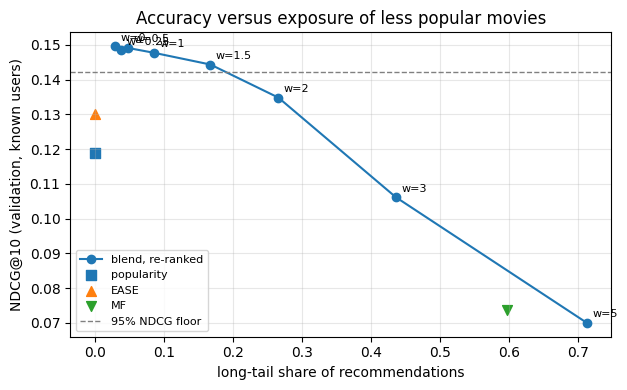

**Interpretation:** Re-ranking with w=1.5 keeps NDCG@10 at 0.144 (96.5% of the un-re-ranked blend). It raises the long-tail share from 2.9% to 16.7% and catalog coverage from 6.3% to 9.9%. Larger weights trade accuracy away quickly, so the weight is a product decision; the rule makes it explicit.

In [7]:
fig, axis = plt.subplots(figsize=(6.4, 4))
axis.plot(rerank_grid.long_tail_share, rerank_grid.ndcg, marker="o", color="tab:blue", label="blend, re-ranked")
for weight, row in rerank_grid.iterrows():
    axis.annotate(f"w={weight:g}", (row.long_tail_share, row.ndcg), textcoords="offset points", xytext=(4, 4), fontsize=8)
for name, marker in [("popularity", "s"), ("EASE", "^"), ("MF", "v")]:
    axis.scatter(val_table.loc[name, "long_tail_share"], val_table.loc[name, "ndcg"], marker=marker, s=50, label=name)
axis.axhline(floor, color="grey", ls="--", lw=1, label="95% NDCG floor")
axis.set(xlabel="long-tail share of recommendations", ylabel="NDCG@10 (validation, known users)",
         title="Accuracy versus exposure of less popular movies")
axis.grid(alpha=0.3)
axis.legend(fontsize=8)
fig.tight_layout()
plt.show()
chosen = rerank_grid.loc[WEIGHT]
display(Markdown(
    f"**Interpretation:** Re-ranking with w={WEIGHT:g} keeps NDCG@10 at {chosen.ndcg:.3f} "
    f"({chosen.ndcg / rerank_grid.loc[0, 'ndcg']:.1%} of the un-re-ranked blend). It raises the long-tail share from "
    f"{rerank_grid.loc[0, 'long_tail_share']:.1%} to {chosen.long_tail_share:.1%} and catalog coverage from "
    f"{rerank_grid.loc[0, 'coverage']:.1%} to {chosen.coverage:.1%}. Larger weights trade accuracy away quickly, "
    "so the weight is a product decision; the rule makes it explicit."))

## Test evaluation

All settings are now fixed (EASE penalty, α, w, the recency variant's settings, and the
rating-model settings from notebook 5). We refit on train + validation and score the test
split. For the recency variant, ages are measured back from the end of the validation period.

In [8]:
history = pd.concat([train, validation], ignore_index=True)
final_bias = BiasModel(**ratings["bias"]).fit(history.user_id, history.movie_id, history.rating)
final_mf = MatrixFactorization(**mf_params).fit(history.user_id, history.movie_id, history.rating)
final_ease = EASE(reg=EASE_REG).fit(history.user_id, history.movie_id)
final_ease_recent = final_ease if RECENT_REG == EASE_REG else EASE(reg=RECENT_REG).fit(history.user_id, history.movie_id)
tst = RankingData(history, test, final_mf, final_ease)
test_scores = model_scores(tst, final_mf, final_ease, final_ease_recent, final_bias, ALPHA, RECENT_ALPHA,
                           RECENT_HALF_LIFE)
test_lists = {name: tst.ranked(matrix) for name, matrix in test_scores.items()}
test_lists["blend + re-rank"] = tst.ranked(known_ranked=rerank_by_popularity(
    test_scores["blend"], tst.exclude[tst.known], tst.popularity, WEIGHT, K))
test_known = pd.DataFrame({name: tst.evaluate(lists, "known") for name, lists in test_lists.items()}).T
test_all = pd.DataFrame({name: tst.evaluate(lists, "all") for name, lists in test_lists.items()}).T
new_users = tst.evaluate(test_lists["popularity"], "new")
print(f"Test users with a 4-5 star rating: {len(tst.users):,} ({tst.known.sum():,} known, {(~tst.known).sum():,} new)")
print("Known users:")
display(test_known)
print("All users (new users receive the popularity list):")
display(test_all[["users", "precision", "recall", "ndcg", "hit", "coverage", "long_tail_share"]])

Test users with a 4-5 star rating: 1,187 (1,158 known, 29 new)
Known users:


,users,precision,recall,ndcg,hit,coverage,long_tail_share,mean_ratings_per_recommended_movie,genre_diversity
popularity,1158.0000,0.1855,0.0520,0.2009,0.6244,0.0400,0.0000,2298.9521,0.7644
highest rated,1158.0000,0.0746,0.0192,0.0647,0.3895,0.0139,0.6498,756.8502,0.8818
MF,1158.0000,0.1121,0.0386,0.1168,0.4965,0.1601,0.6078,755.7965,0.8048
EASE,1158.0000,0.2016,0.0642,0.2226,0.6520,0.0813,0.0023,2000.1819,0.7855
EASE + recency,1158.0000,0.1837,0.0638,0.2049,0.6425,0.1843,0.0833,1693.3041,0.7397
blend,1158.0000,0.2326,0.0763,0.2575,0.6874,0.0829,0.0312,1878.6550,0.8034
blend + recency,1158.0000,0.2174,0.0743,0.2429,0.6848,0.1528,0.0670,1762.7704,0.7632
blend + re-rank,1158.0000,0.2115,0.0697,0.2354,0.6667,0.1291,0.1807,1587.1751,0.8067


All users (new users receive the popularity list):


,users,precision,recall,ndcg,hit,coverage,long_tail_share
popularity,1187.0000,0.1919,0.0526,0.2072,0.6310,0.0400,0.0000
highest rated,1187.0000,0.0837,0.0205,0.0744,0.4019,0.0163,0.6340
MF,1187.0000,0.1203,0.0395,0.1251,0.5063,0.1601,0.5929
EASE,1187.0000,0.2077,0.0645,0.2284,0.6580,0.0813,0.0023
EASE + recency,1187.0000,0.1901,0.0641,0.2111,0.6487,0.1843,0.0813
blend,1187.0000,0.2379,0.0763,0.2625,0.6925,0.0829,0.0304
blend + recency,1187.0000,0.2230,0.0744,0.2482,0.6900,0.1528,0.0654
blend + re-rank,1187.0000,0.2173,0.0699,0.2408,0.6723,0.1291,0.1762


### How certain are the test differences?

We resample the known test users 2,000 times (paired bootstrap) and recompute the mean
NDCG@10 difference between two lists on the same users. An interval that excludes 0
is a reliable difference.

In [9]:
per_user = {name: tst.user_ndcg(lists) for name, lists in test_lists.items()}
pairs = [("blend", "popularity"), ("blend", "EASE"), ("blend + re-rank", "blend"),
         ("blend + recency", "blend"), ("EASE + recency", "EASE")]
bootstrap = {f"{a} vs {b}": paired_bootstrap(per_user[a], per_user[b]) for a, b in pairs}
bootstrap_table = pd.DataFrame(bootstrap).T.rename(columns={"difference": "NDCG@10 difference"})
display(bootstrap_table)
def verdict(result):
    if result["ci_low"] > 0:
        return "a reliable gain"
    if result["ci_high"] < 0:
        return "a reliable loss"
    return "not distinguishable from 0"


recency = bootstrap["blend + recency vs blend"]
popular = bootstrap["blend vs popularity"]
display(Markdown(
    f"**Interpretation:** The blend beats popularity by {popular['difference']:+.4f} NDCG@10 "
    f"(95% interval {popular['ci_low']:+.4f} to {popular['ci_high']:+.4f}): {verdict(popular)}. "
    f"Adding recency changes the blend's test NDCG@10 by {recency['difference']:+.4f} "
    f"({recency['ci_low']:+.4f} to {recency['ci_high']:+.4f}): {verdict(recency)}, although it won on validation."))

,NDCG@10 difference,ci_low,ci_high
blend vs popularity,0.0567,0.0472,0.0660
blend vs EASE,0.0349,0.0263,0.0429
blend + re-rank vs blend,-0.0222,-0.0261,-0.0182
blend + recency vs blend,-0.0146,-0.0234,-0.0059
EASE + recency vs EASE,-0.0178,-0.0266,-0.0094


**Interpretation:** The blend beats popularity by +0.0567 NDCG@10 (95% interval +0.0472 to +0.0660): a reliable gain. Adding recency changes the blend's test NDCG@10 by -0.0146 (-0.0234 to -0.0059): a reliable loss, although it won on validation.

### Why did recency fail on test? A horizon check

Validation covers four weeks after its cutoff; test covers two years. Recent ratings may
predict what a user rates *next* but not over two years. We keep the test lists fixed and
score them against only the first 7, 28, 90 and 365 days of test ratings. Nothing is
re-tuned; this is a diagnosis, not a selection.

In [10]:
horizon_rows = []
for days in [7, 28, 90, 365, None]:
    window = test if days is None else test.loc[test.timestamp <= history.timestamp.max() + days * 86400]
    part = RankingData(history, window, final_mf, final_ease)
    part_scores = model_scores(part, final_mf, final_ease, final_ease_recent, final_bias, ALPHA, RECENT_ALPHA,
                               RECENT_HALF_LIFE)
    with_recency, without = (part.user_ndcg(part.ranked(part_scores[name])) for name in ["blend + recency", "blend"])
    result = paired_bootstrap(with_recency, without)
    horizon_rows.append({"horizon (days)": "full test" if days is None else days, "users": int(part.known.sum()),
                         "blend + recency": with_recency.mean(), "blend": without.mean(), **result})
horizon = pd.DataFrame(horizon_rows).set_index("horizon (days)")
display(horizon)
short = horizon.iloc[0]
display(Markdown(
    f"**Interpretation:** Over the first {horizon.index[0]} days, recency changes NDCG@10 by {short.difference:+.4f} "
    f"({short.ci_low:+.4f} to {short.ci_high:+.4f}"
    + ("; the interval only just reaches 0, so this is borderline" if -0.002 < short.ci_low <= 0 else "")
    + f"); over the full test period by {horizon.iloc[-1].difference:+.4f}. "
    "The sign moves from positive at short horizons to negative over the long test window, which fits the "
    + ("explanation, but no test horizon shows a clear gain. " if (horizon.ci_low <= 0).all() else
       "explanation; short horizons show a reliable gain. ")
    + "Over the two-year evaluation the final ranker would lose accuracy, so it does not use recency. "
    "A live service that refreshes lists daily would face the short horizon, so the idea may still deserve a test "
    "on data with frequent re-ranking."))

,users,blend + recency,blend,difference,ci_low,ci_high
horizon (days),,,,,,
7,207,0.1067,0.0872,0.0196,-0.0000,0.0388
28,502,0.1329,0.1245,0.0084,-0.0035,0.0206
90,759,0.1544,0.1507,0.0038,-0.0056,0.0132
365,1049,0.2048,0.2101,-0.0053,-0.0140,0.0036
full test,1158,0.2429,0.2575,-0.0146,-0.0234,-0.0059


**Interpretation:** Over the first 7 days, recency changes NDCG@10 by +0.0196 (-0.0000 to +0.0388; the interval only just reaches 0, so this is borderline); over the full test period by -0.0146. The sign moves from positive at short horizons to negative over the long test window, which fits the explanation, but no test horizon shows a clear gain. Over the two-year evaluation the final ranker would lose accuracy, so it does not use recency. A live service that refreshes lists daily would face the short horizon, so the idea may still deserve a test on data with frequent re-ranking.

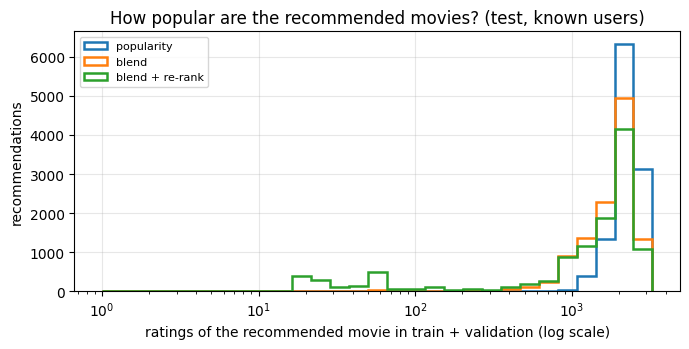

**Interpretation:** On the test split, the best NDCG@10 for known users comes from **blend** (0.258). Popularity scores 0.201, the blend 0.258, and the re-ranked blend 0.235, which recommends 12.9% of the catalog (popularity: 4.0%) with a long-tail share of 18.1%. On test, re-ranking keeps 91.4% of the blend's NDCG@10, against 96.5% on validation: the accuracy cost of exposure is larger over the long test period than the 95% rule anticipated. The 29 users who were new at the cutoff receive popularity lists (NDCG@10 0.459). The test period runs for two years after a short validation month, so these absolute values are not comparable with random-split results reported elsewhere.

In [11]:
fig, axis = plt.subplots(figsize=(7, 3.6))
bins = np.logspace(0, np.log10(tst.counts.max() + 1), 30)
for name in ["popularity", "blend", "blend + re-rank"]:
    known_lists = test_lists[name][tst.known].ravel()
    axis.hist(tst.counts[known_lists] + 1, bins=bins, histtype="step", lw=1.8, label=name)
axis.set_xscale("log")
axis.set(xlabel="ratings of the recommended movie in train + validation (log scale)",
         ylabel="recommendations", title="How popular are the recommended movies? (test, known users)")
axis.legend(fontsize=8)
axis.grid(alpha=0.3)
fig.tight_layout()
plt.show()
best_test = test_known.ndcg.idxmax()
display(Markdown(
    f"**Interpretation:** On the test split, the best NDCG@10 for known users comes from **{best_test}** "
    f"({test_known.loc[best_test, 'ndcg']:.3f}). Popularity scores {test_known.loc['popularity', 'ndcg']:.3f}, the "
    f"blend {test_known.loc['blend', 'ndcg']:.3f}, and the re-ranked blend {test_known.loc['blend + re-rank', 'ndcg']:.3f}, "
    f"which recommends {test_known.loc['blend + re-rank', 'coverage']:.1%} of the catalog (popularity: "
    f"{test_known.loc['popularity', 'coverage']:.1%}) with a long-tail share of "
    f"{test_known.loc['blend + re-rank', 'long_tail_share']:.1%}. On test, re-ranking keeps "
    f"{test_known.loc['blend + re-rank', 'ndcg'] / test_known.loc['blend', 'ndcg']:.1%} of the blend's NDCG@10, "
    f"against {rerank_grid.loc[WEIGHT, 'ndcg'] / rerank_grid.loc[0, 'ndcg']:.1%} on validation"
    + (": the accuracy cost of exposure is larger over the long test period than the 95% rule anticipated. "
       if test_known.loc['blend + re-rank', 'ndcg'] / test_known.loc['blend', 'ndcg'] < 0.95 else
       ", so the 95% rule also holds on test. ")
    + f"The {new_users['users']:,} users who were new "
    f"at the cutoff receive popularity lists (NDCG@10 {new_users['ndcg']:.3f}). The test period runs for two years "
    "after a short validation month, so these absolute values are not comparable with random-split results "
    "reported elsewhere."))

In [12]:
summary = {"k": K, "relevant_stars": RELEVANT_STARS, "min_support": MIN_SUPPORT,
           "selected": {"ease_reg": EASE_REG, "alpha": ALPHA, "half_life_days": HALF_LIFE,
                        "rerank_weight": WEIGHT, "rerank_depth": 100},
           "recency_variant": {"used": False, "ease_reg": RECENT_REG, "alpha": RECENT_ALPHA,
                               "half_life_days": RECENT_HALF_LIFE, "validation_ndcg": float(recent.ndcg),
                               "reason": "reliably lower test NDCG@10; decision informed by the test split"},
           "test_bootstrap": bootstrap,
           "recency_horizons": horizon.reset_index().astype({"horizon (days)": str}).to_dict(orient="records"),
           "blend_grid": blend_grid.to_dict(orient="records"),
           "rerank_grid": rerank_grid.reset_index().to_dict(orient="records"),
           "validation_known_users": val_table.to_dict(orient="index"),
           "test_known_users": test_known.to_dict(orient="index"),
           "test_all_users": test_all.to_dict(orient="index"),
           "test_new_users_popularity": new_users}
(PROCESSED / "ranking_summary.json").write_text(json.dumps(summary, indent=2) + "\n", encoding="utf-8")
print("Saved ranking_summary.json to data/processed/.")

Saved ranking_summary.json to data/processed/.


Notebook 7 explains these recommendations: which of a user's own ratings put each movie
on the list, and whether removing that rating would really change it.